<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS06/datasetPBL/Praktikum1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# import package
import numpy as np
import pandas as pd

In [2]:
# baca data dari file CSV dan gabungkan
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')

data = pd.merge(
    df_reviews,
    df_cafes,
    on='cafe_id',
    how='left',
    suffixes=('_review', '_cafe')
)

In [3]:
# melihat beberapa data awal
data.head()

# mengecek ukuran data
data.shape

# informasi tentang data
data.info()

# deskripsi data
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2230 entries, 0 to 2229
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   review_id          2230 non-null   object 
 1   cafe_id            2230 non-null   object 
 2   author_name        2230 non-null   object 
 3   rating_review      2230 non-null   float64
 4   text               2230 non-null   object 
 5   published_at       2230 non-null   object 
 6   likes              2230 non-null   int64  
 7   scraped_at_review  2230 non-null   object 
 8   name               2230 non-null   object 
 9   address            2230 non-null   object 
 10  latitude           2230 non-null   float64
 11  longitude          2230 non-null   float64
 12  rating_cafe        2230 non-null   float64
 13  review_count       2230 non-null   int64  
 14  categories         2230 non-null   object 
 15  phone              1658 non-null   object 
 16  website            1230 

,rating_review,likes,latitude,longitude,rating_cafe,review_count
count,2230.000000,2230.000000,2230.000000,2230.000000,2230.000000,2230.000000
mean,4.553363,0.037220,-7.964982,112.627947,4.647623,933.663677
std,1.076097,0.255852,0.010956,0.007640,0.165432,1225.834779
min,1.000000,0.000000,-7.985575,112.607256,4.200000,1.000000
25%,5.000000,0.000000,-7.972556,112.622708,4.600000,166.000000
50%,5.000000,0.000000,-7.967474,112.628375,4.700000,540.000000
75%,5.000000,0.000000,-7.961124,112.633083,4.700000,1105.000000
max,5.000000,4.000000,-7.932842,112.651831,5.000000,6014.000000


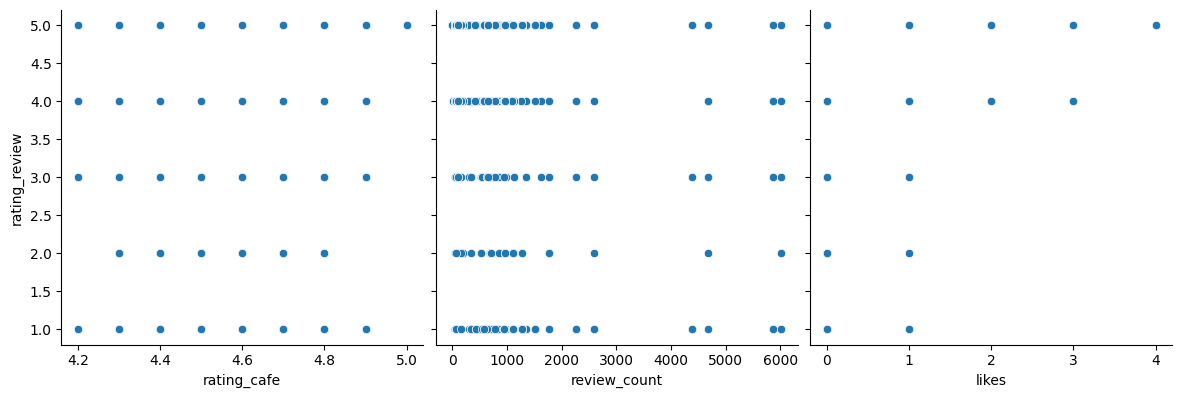

In [4]:
# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# visualisasi data dengan pairplot
sns.pairplot(data, x_vars=['rating_cafe', 'review_count', 'likes'],
             y_vars='rating_review', height=4, aspect=1, kind='scatter')
plt.show()

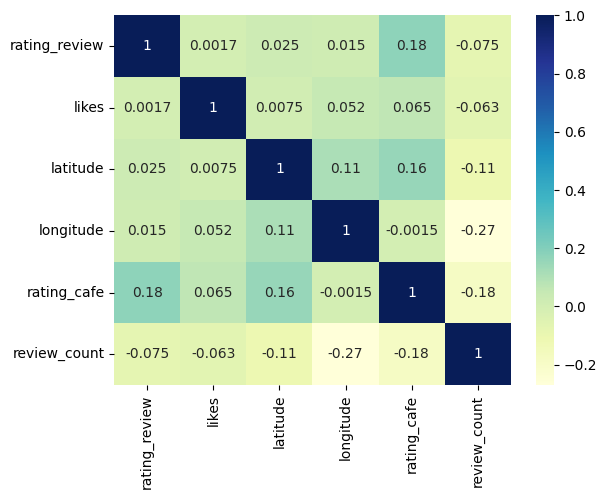

In [5]:
# visualisasi korelasi dengan heatmap
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.show()

In [6]:
# Membuat variabel bebas X dan Y, contoh pengambilan dari analisis korelasi sebelumnya
X = data['rating_cafe']
y = data['rating_review']

In [7]:
# Pembagian data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

In [8]:
# Training model
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()
lr.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          rating_review   R-squared:                       0.035
Model:                            OLS   Adj. R-squared:                  0.034
Method:                 Least Squares   F-statistic:                     56.74
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           8.37e-14
Time:                        14:35:46   Log-Likelihood:                -2334.1
No. Observations:                1561   AIC:                             4672.
Df Residuals:                    1559   BIC:                             4683.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -1.2257      0.765     -1.602      0.109      -2.726       0.275
rating_cafe     1.2389      0.164      7.533      0.000       0.916       1.562
==============================================================================
Omnibus:                      716.931   Durbin-Watson:                   2.071
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2710.410
Skew:                          -2.332   Prob(JB):                         0.00
Kurtosis:                       7.463   Cond. No.                         136.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

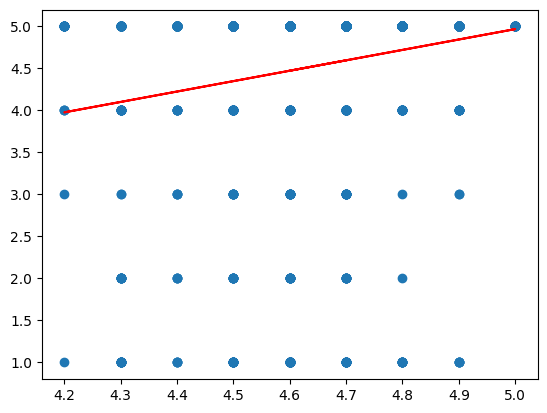

In [9]:
# Visualisasi garis regresi
plt.scatter(X_train, y_train)
plt.plot(X_train, -1.2257 + 1.2389*X_train, 'r')
plt.show()

In [10]:
# Prediksi nilai y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual
res = (y_train - y_train_pred)

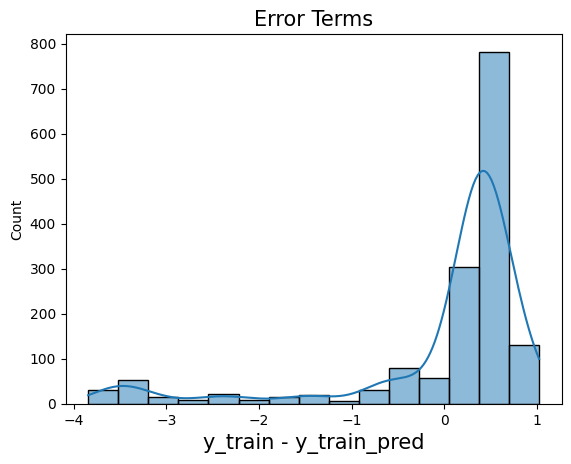

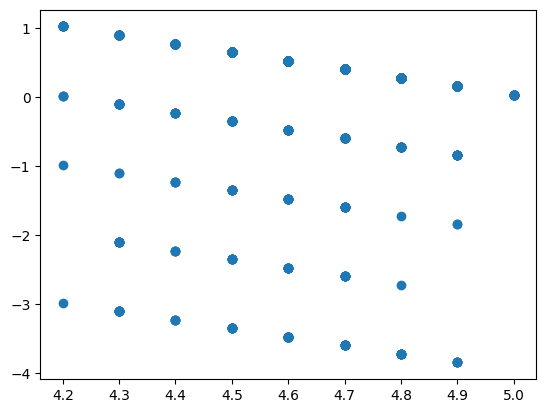

In [11]:
# Histogram residual
fig = plt.figure()
sns.histplot(res, bins=15, kde=True)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

# Scatter plot residual
plt.scatter(X_train, res)
plt.show()

In [12]:
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

In [13]:
# Hitung nilai R-squared
from sklearn.metrics import r2_score

r_squared = r2_score(y_test, y_test_pred)
r_squared

0.015215365356628485

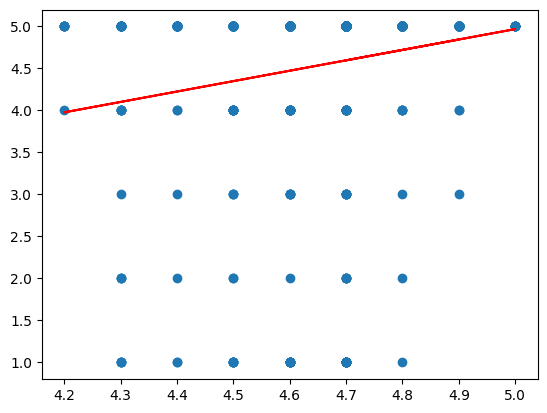

In [14]:
# Visualisasi data uji dan hasil prediksi
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.show()